In [1]:
# Assignment 1, Exercise 3 b) (i)
# Participant_ID 25: bundles from the rounds that contain (2,2), split into
# "better" and "worse" than (2,2), with one indifference curve through (2,2).
# Colours follow the lecture figures (L1-L3). Font: Cambria, as in the text
# of the assignment.

# =============================================================================
# 1. Libraries
# =============================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D      # legend symbols for points and lines
from matplotlib.patches import Patch     # legend symbol for the hatched area

# Folder of this script (or of the notebook in Jupyter). The PNG is saved here.
try:
    FOLDER = os.path.dirname(os.path.abspath(__file__))   # run as a .py file
except NameError:
    FOLDER = os.getcwd()                                  # Jupyter: folder of the notebook

In [2]:
# =============================================================================
# 2. Utility function and indifference curve
# =============================================================================
# Cobb-Douglas utility from the lecture: u(x1, x2) = x1^alpha * x2^(1 - alpha).
# Part (ii) shows that every alpha with 0 < alpha < 1/2 reproduces her answers.
# We draw the curve for one value inside this range, alpha = 1/3.
ALPHA = 1 / 3

def u(x1, x2, alpha=ALPHA):
    return x1 ** alpha * x2 ** (1 - alpha)

U0 = u(2, 2)        # utility of the reference bundle; equals 2 for every alpha

def indifference_curve(x1, level=U0, alpha=ALPHA):
    # Solve u(x1, x2) = level for x2.
    return (level / x1 ** alpha) ** (1 / (1 - alpha))

# With alpha = 1/3 and U0 = 2 the curve is x1 * x2^2 = 8, i.e. x2 = sqrt(8 / x1).
x1_grid = np.linspace(0.35, 4.85, 400)   # start above 0: the curve goes to infinity at x1 = 0
x2_curve = indifference_curve(x1_grid)

In [3]:
# =============================================================================
# 3. Bundles from the data
# =============================================================================
# (x1, x2, round), taken from Preference_Experiment_Data.xlsx, Participant_ID 25.
better = [(4, 4, 'R3'), (1, 4, 'R4'), (2, 4, 'R7')]                                 # chosen over (2,2)
worse  = [(4, 0, 'R1'), (0, 4, 'R2'), (4, 1, 'R5'), (2, 1, 'R9'), (2, 0.5, 'R13')]  # (2,2) chosen

# Check: the curve separates the two groups (better above it, worse below it).
assert all(u(a, b) > U0 for a, b, _ in better)
assert all(u(a, b) < U0 for a, b, _ in worse)

In [4]:
# =============================================================================
# 4. Chart set-up: font, colours, axes
# =============================================================================
# Font: Cambria only, also for x1, x2 and the numbers. Cambria comes with
# Windows and MS Office, so no font file is needed.
FONT = 'Cambria'
if FONT not in {f.name for f in fm.fontManager.ttflist}:
    raise RuntimeError(f'{FONT} is not installed on this computer.')
plt.rcParams.update({
    'font.family': FONT,
    'font.size': 10,
    'hatch.linewidth': 0.6,
})

# Cambria also contains small bitmap copies of its letters for screens. At small
# sizes (about 6-7 pt at 200 dpi) matplotlib picks these bitmaps but cannot place
# them, so subscripts and superscripts vanish and a stray digit appears in a
# corner. Tell matplotlib to always draw the normal outline letters instead.
from matplotlib.backends import backend_agg
from matplotlib.ft2font import LoadFlags
if not getattr(backend_agg.get_hinting_flag, 'no_bitmap', False):   # patch only once
    _hinting_flag = backend_agg.get_hinting_flag
    def _outline_only_flag():
        return _hinting_flag() | LoadFlags.NO_BITMAP
    _outline_only_flag.no_bitmap = True
    backend_agg.get_hinting_flag = _outline_only_flag

# Colours from the lecture slides.
TEXT  = '#212121'   # text, axes, the bundle (2,2)
GREY  = '#6E6E6E'   # dashed guide lines
IC    = '#0072B2'   # indifference curve
GREEN = '#4CA64C'   # hatched "better" area (L1, slide 11)
DKGRN = '#006600'   # better bundles
RED   = '#9B192D'   # worse bundles (L1, slide 32)

# Text with subscripts and superscripts, e.g. x1 x2^2 = 8.
# Each piece is plain Cambria text placed right after the piece before it,
# so the figure does not need matplotlib's math renderer.
# parts: list of (text, kind) with kind None, 'sub' or 'sup'.
def rich_text(ax, x, y, parts, coords='data', size=10, color=None):
    color = color or TEXT
    small = 0.7 * size
    base = ax.annotate(parts[0][0], (x, y), xycoords=coords, fontsize=size,
                       color=color, va='bottom', annotation_clip=False)
    last, last_kind = base, None
    for text, kind in parts[1:]:
        if kind == 'sub':
            y_rel, shift, fs = 0, -2.5, small     # lower, smaller
        elif kind == 'sup':
            y_rel, shift, fs = 0.4, 0, small      # higher, smaller
        else:
            y_rel, shift, fs = 0, 0, size         # same line as the first piece
        # a superscript right after a subscript sits above it (x2^2), not after it
        x_rel = 0 if (kind == 'sup' and last_kind == 'sub') else 1
        last = ax.annotate(text, (x_rel, y_rel), xycoords=(last, base), xytext=(0.3 * x_rel, shift),
                           textcoords='offset points', fontsize=fs, color=color,
                           va='bottom', annotation_clip=False)
        last_kind = kind
    return base

fig, ax = plt.subplots(figsize=(4.4, 3.55), dpi=200)

# Axes as on the slides: only left and bottom lines, arrows at the ends.
ax.set_xlim(0, 5.0)
ax.set_ylim(0, 5.0)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax.spines[side].set_color(TEXT)
ax.plot(1, 0, '>', color=TEXT, transform=ax.transAxes, clip_on=False, ms=5)
ax.plot(0, 1, '^', color=TEXT, transform=ax.transAxes, clip_on=False, ms=5)
ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.tick_params(colors=TEXT, labelsize=9)
rich_text(ax, 0.84, -0.17, [('x', None), ('1', 'sub'), (' (apples)', None)], coords='axes fraction')
rich_text(ax, -0.11, 1.03, [('x', None), ('2', 'sub'), (' (bananas)', None)], coords='axes fraction')
plt.close(fig)

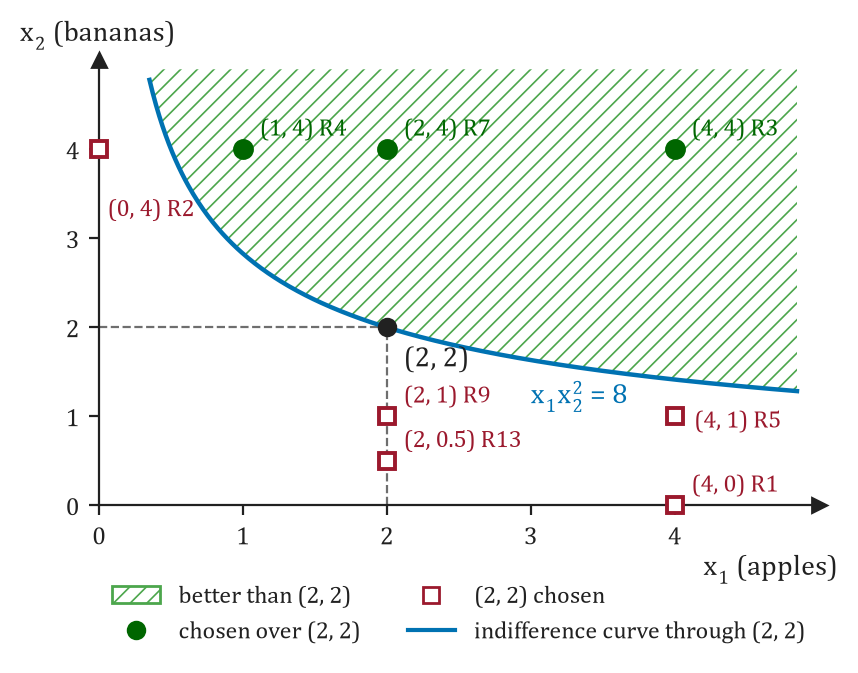

In [5]:
# =============================================================================
# 5. Draw and export
# =============================================================================
# Better set: everything above the indifference curve (hatched).
ax.fill_between(x1_grid, x2_curve, 4.9, facecolor='none', edgecolor=GREEN,
                hatch='////', lw=0, zorder=0)
ax.plot(x1_grid, x2_curve, color=IC, lw=1.6, zorder=2)
rich_text(ax, 3.0, 1.08, [('x', None), ('1', 'sub'), ('x', None), ('2', 'sub'), ('2', 'sup'),
                         (' = 8', None)], color=IC)

# Dashed guide lines from the axes to (2,2).
ax.plot([2, 2], [0, 2], ls='--', lw=0.8, color=GREY, zorder=1)
ax.plot([0, 2], [2, 2], ls='--', lw=0.8, color=GREY, zorder=1)

# Bundles with labels "(x1, x2) round"; labels sit 6 pt right and 5 pt up.
for a, b, r in better:
    ax.plot(a, b, 'o', color=DKGRN, ms=6.5, zorder=3)
    ax.annotate(f'({a:g}, {b:g}) {r}', (a, b), xytext=(6, 5),
                textcoords='offset points', fontsize=8.5, color=DKGRN)

label_offset = {(0, 4): (3, -24),      # R2 label below the point, off the curve
                (4, 1): (7, -4)}       # R5 label a bit lower, off the curve
for a, b, r in worse:
    ax.plot(a, b, 's', mfc='white', mec=RED, mew=1.4, ms=6, zorder=3, clip_on=False)
    ax.annotate(f'({a:g}, {b:g}) {r}', (a, b), xytext=label_offset.get((a, b), (6, 5)),
                textcoords='offset points', fontsize=8.5, color=RED)

ax.plot(2, 2, 'o', color=TEXT, ms=6, zorder=4)
ax.annotate('(2, 2)', (2, 2), xytext=(6, -14), textcoords='offset points', color=TEXT)

# Legend below the chart.
legend = [Patch(facecolor='none', edgecolor=GREEN, hatch='////', label='better than (2, 2)'),
          Line2D([], [], marker='o', ls='', color=DKGRN, label='chosen over (2, 2)'),
          Line2D([], [], marker='s', ls='', mfc='white', mec=RED, label='(2, 2) chosen'),
          Line2D([], [], color=IC, label='indifference curve through (2, 2)')]
ax.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.5, -0.13),
          ncol=2, frameon=False, fontsize=8.5, labelcolor=TEXT)

fig.tight_layout()
fig.savefig(os.path.join(FOLDER, 'A1_Ex3b_figure.png'))
fig